In [1]:
# Macro controls: VIX and the 10-year Treasury yield (Sections 3.2.4 and 3.2.5)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The clean files are saved straight into the folder with the regression notebooks
OUT = "../Regressions and relevant csvs/"

In [2]:
# VIX: month-end close (CBOE Indexes via WRDS), monthly change in logs
vix = pd.read_excel("VIX Monthly.xlsx")
vix = pd.DataFrame({
    "date": pd.to_datetime(vix.iloc[:, 0]) + pd.offsets.MonthEnd(0),
    "vix": vix.iloc[:, 1],
}).sort_values("date").reset_index(drop=True)
vix["dlog_vix"] = np.log(vix["vix"]).diff()

# 10-year Treasury yield in percent (FRED, DGS10, end of month), monthly change in percentage points.
# FRED dates each month with its first day, so the date is moved to the month end.
dgs10 = pd.read_excel("DGS10 Monthly.xlsx")
dgs10 = pd.DataFrame({
    "date": pd.to_datetime(dgs10["observation_date"]) + pd.offsets.MonthEnd(0),
    "dgs10": dgs10["DGS10"],
}).sort_values("date").reset_index(drop=True)
dgs10["d_dgs10"] = dgs10["dgs10"].diff()

vix = vix.dropna().reset_index(drop=True)
dgs10 = dgs10.dropna().reset_index(drop=True)
print("VIX:", len(vix), "months, DGS10:", len(dgs10), "months")
pd.concat([vix["dlog_vix"].describe(), dgs10["d_dgs10"].describe()], axis=1).round(3)

VIX: 121 months, DGS10: 121 months


,dlog_vix,d_dgs10
count,121.000,121.000
mean,-0.001,0.016
std,0.232,0.242
min,-0.614,-0.520
25%,-0.134,-0.120
50%,-0.004,0.010
75%,0.121,0.160
max,0.756,0.680


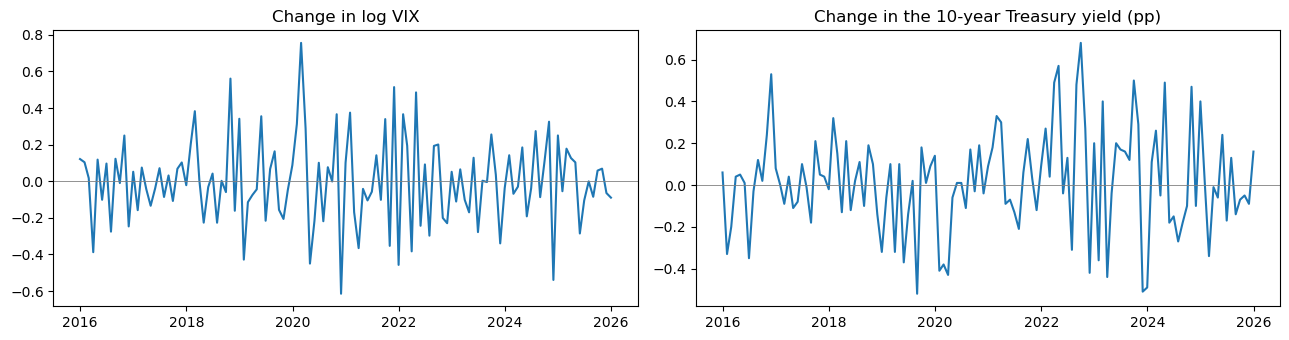

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(vix["date"], vix["dlog_vix"])
axes[0].set_title("Change in log VIX")
axes[1].plot(dgs10["date"], dgs10["d_dgs10"])
axes[1].set_title("Change in the 10-year Treasury yield (pp)")
for ax in axes:
    ax.axhline(0, color="grey", lw=0.6)
plt.tight_layout()
plt.show()

In [4]:
vix[["date", "dlog_vix"]].to_csv(OUT + "vix_clean.csv", index=False)
dgs10[["date", "d_dgs10"]].to_csv(OUT + "dgs10_clean.csv", index=False)